In [1]:
# notebook 06, invisible breaks: whose broken routine does a disruption alarm see, and whose stays invisible? Kernel: Python (yjmob)
# James C. Scott (Seeing Like a State, 1998) argued that a state sees what it has made legible: lives simplified to fit its grid. A disruption
# alarm is such a grid. This notebook measures who is legible to it, why, what a fairer design changes, and what no design can fix.
# It reads only what notebooks 04 and 05 saved, so it runs in a minute or two on CPU
import sys, json, time, zipfile
from pathlib import Path
ROOT = Path("/projects/ancz7294/yjmob")
sys.path.insert(0, str(ROOT / "code"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from breaks import cusum, alarm_onset
PROC, FIG, OUT = ROOT / "data/processed", ROOT / "figures", ROOT / "exports"
OUT.mkdir(exist_ok=True)
SEED = 20260917
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
    "font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
def save(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)
ORDER = ["far roamers", "mid-range movers", "regular commuters", "local regulars", "weekend movers", "homebodies"]
GREY, VERM, VERM_LIGHT = "#7d838c", C[1], "#f6c9b6"
lab = pd.read_parquet(PROC / "person_breaks.parquet")             # notebook 04: did each person's habit agent break (60-74 against 45-59, above the placebo line)
T = pd.read_parquet(PROC / "who_breaks_table.parquet")              # notebook 04: traits from days 0-44, including regularity
L = pd.read_parquet(PROC / "day_evidence_eval.parquet"); L.columns = L.columns.astype(int)   # notebook 04: each evaluation person's evidence for 'emergency', day by day
ev = lab[lab.split == "eval"][["kind", "delta", "broke"]].join(T["regularity"]).join(L, how="inner")
ev["broke"] = ev.broke.astype(bool)
FIFTH = ["least regular", "2nd", "3rd", "4th", "most regular"]
ev["fifth"] = pd.qcut(ev.regularity, 5, labels=FIFTH)
A = ev[list(range(75))].astype(float)                               # days as columns; NaN where a day had too few records
LOG = {"people": len(ev), "broke_share": round(float(ev.broke.mean()), 4)}
print(f"{len(ev):,} evaluation people with a label and daily evidence, {ev.broke.mean():.1%} broke")
print(ev.groupby("fifth", observed=True).agg(people=("broke", "size"), regularity=("regularity", "median"), broke=("broke", "mean")).round(3).to_string())

7,135 evaluation people with a label and daily evidence, 18.9% broke
               people  regularity  broke
fifth                                   
least regular    1427       0.139  0.130
2nd              1441       0.321  0.155
3rd              1436       0.500  0.162
4th              1409       0.701  0.197
most regular     1422       0.915  0.300


one scale for everyone: k 0.2, h 7.52 | breaks seen 0.358, held flagged 0.082
               broke  breaks seen  held but flagged  false alarm, days 45-59
fifth                                                                       
least regular  0.130        0.043             0.015                    0.001
2nd            0.155        0.174             0.057                    0.019
3rd            0.162        0.246             0.110                    0.047
4th            0.197        0.448             0.125                    0.078
most regular   0.300        0.595             0.115                    0.092
                   broke  breaks seen
kind                                 
far roamers        0.153        0.065
mid-range movers   0.131        0.077
regular commuters  0.291        0.641
local regulars     0.200        0.398
weekend movers     0.200        0.755
homebodies         0.209        0.260


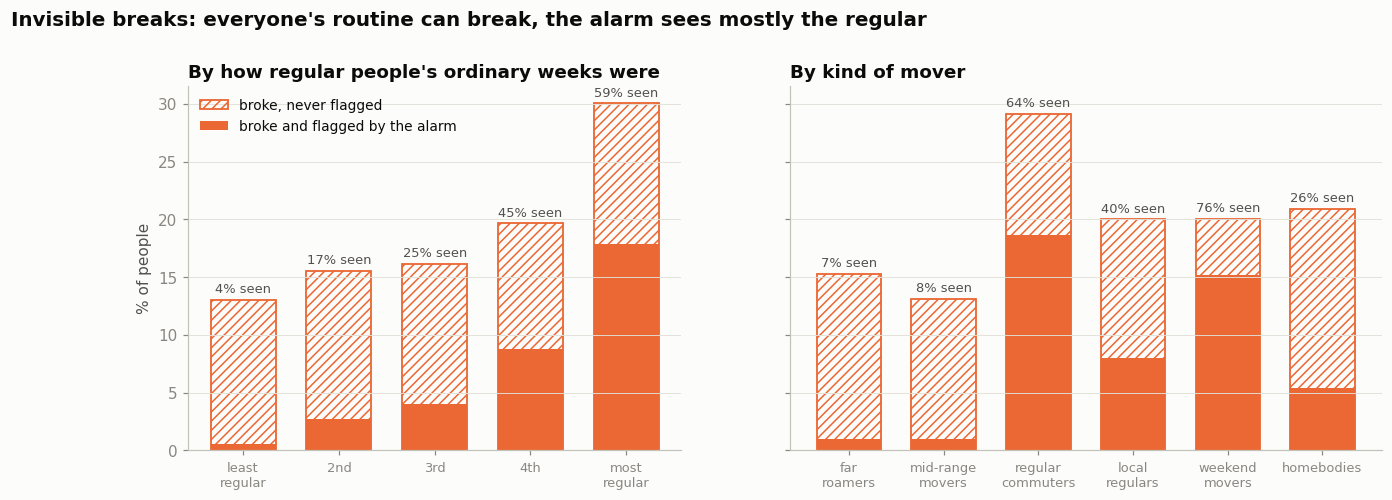

In [2]:
# the alarm of notebook 04, one scale for everyone: add up each day's evidence minus k and raise the alarm when the sum passes h.
# h is set so that only 5% of people would be flagged on ordinary days 30-44; monitoring starts on day 45, so an alarm on
# days 45-59 is a false alarm and an alarm on days 60-74 sees the emergency
def run_alarm(Z, k):
    h = np.percentile(cusum(Z.loc[:, 30:44].fillna(0.0), k).max(axis=1), 95)
    path = cusum(Z.loc[:, 45:74].fillna(0.0), k)                    # a day with too few records adds nothing
    alarm, _ = alarm_onset(path, h)
    return alarm, h, path
alarm_one, h_one, path_one = run_alarm(A, 0.2)
ev["seen_one"], ev["early_one"] = alarm_one.between(60, 74), alarm_one.between(45, 59)
def seen_table(col_seen, col_early):
    return ev.groupby("fifth", observed=True).apply(lambda g: pd.Series({
        "broke": g.broke.mean(), "breaks seen": g[col_seen][g.broke].mean(), "held but flagged": g[col_seen][~g.broke].mean(),
        "false alarm, days 45-59": g[col_early].mean()}), include_groups=False)
tab_one = seen_table("seen_one", "early_one")
kind_one = ev.groupby("kind").apply(lambda g: pd.Series({"broke": g.broke.mean(), "breaks seen": g.seen_one[g.broke].mean()}), include_groups=False).reindex(ORDER)
print(f"one scale for everyone: k 0.2, h {h_one:.2f} | breaks seen {ev.seen_one[ev.broke].mean():.3f}, held flagged {ev.seen_one[~ev.broke].mean():.3f}")
print(tab_one.round(3).to_string()); print(kind_one.round(3).to_string())
LOG["one_scale"] = {"h": round(float(h_one), 3), "by_fifth": tab_one.round(4).to_dict(orient="index"), "by_kind": kind_one.round(4).to_dict(orient="index")}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True, gridspec_kw={"width_ratios": [1, 1.2]})
for ax, t_, labels, title in [(axes[0], tab_one, FIFTH, "By how regular people's ordinary weeks were"),
                              (axes[1], kind_one, ORDER, "By kind of mover")]:
    xx = np.arange(len(t_)); seen_pp = t_["broke"] * t_["breaks seen"] * 100; broke_pp = t_["broke"] * 100
    ax.bar(xx, broke_pp, color="none", edgecolor=VERM, hatch="////", lw=1.2, width=0.68, label="broke, never flagged")
    ax.bar(xx, seen_pp, color=VERM, width=0.68, label="broke and flagged by the alarm")
    for x_, b_, s_ in zip(xx, t_["broke"], t_["breaks seen"]):
        ax.text(x_, b_ * 100 + 0.6, f"{s_:.0%} seen", ha="center", fontsize=8.5, color="#52514e")
    ax.set_xticks(xx); ax.set_xticklabels([l_.replace(" ", "\n", 1) for l_ in labels], fontsize=8.5); ax.set_title(title); ax.xaxis.grid(False)
axes[0].set_ylabel("% of people"); axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Invisible breaks: everyone's routine can break, the alarm sees mostly the regular", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.04)
save(fig, "f47_invisible_breaks")

people whose routine broke, by fifth of regularity:
               people  break_size  shift  wobble  d_prime  days_needed  visible_in_15_days
fifth                                                                                     
least regular     186       0.309  0.165   0.316    0.461       29.138               0.398
2nd               224       0.286  0.168   0.466    0.384       41.953               0.371
3rd               232       0.313  0.266   0.529    0.502       24.561               0.414
4th               277       0.309  0.580   0.863    0.730       11.620               0.545
most regular      427       0.371  1.103   1.024    1.060        5.507               0.707


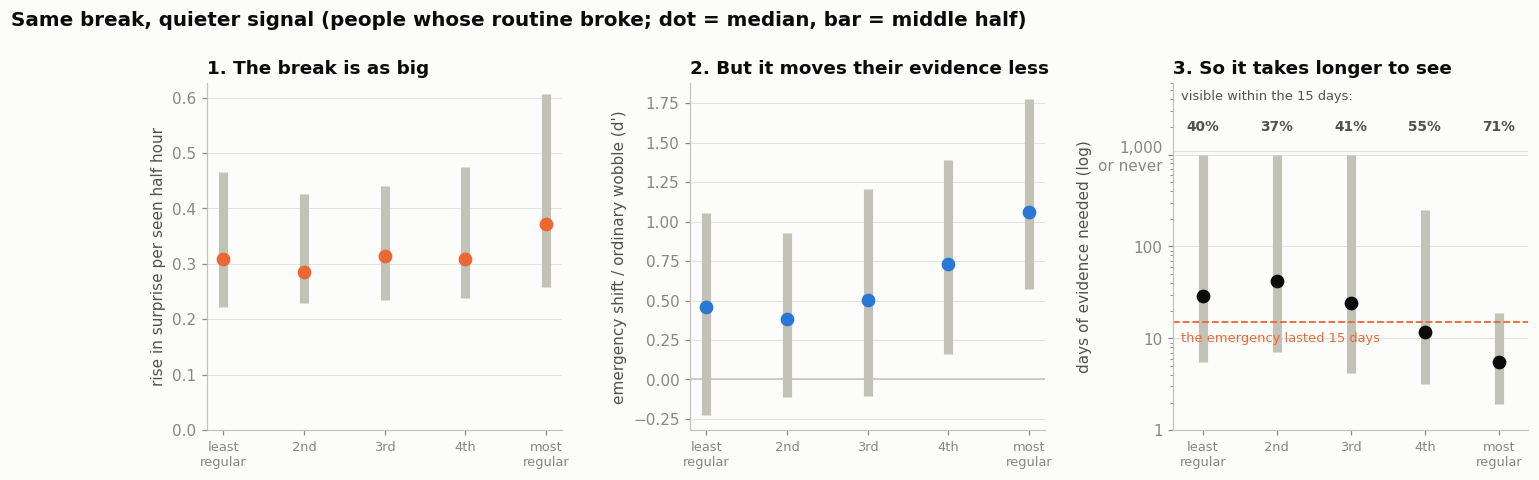

In [3]:
# why: is an irregular person's break smaller, or only harder to see? Break size comes from the habit model (rise in surprise per seen
# half hour, the label of notebook 04). Visibility comes from the daily evidence: how far the emergency days moved it, in units of the
# person's own ordinary day-to-day wobble (d'). Days needed: how many independent days of evidence a test at 5% false alarms and 80%
# power would need to see a shift that size
ordinary = A.loc[:, 0:44]
mu0, sd0 = ordinary.mean(axis=1), ordinary.std(axis=1)
ev["shift"] = A.loc[:, 60:74].mean(axis=1) - mu0
ev["wobble"] = sd0
ev["d_prime"] = ev["shift"] / ev["wobble"]
ev["days_needed"] = np.where(ev.d_prime > 0, ((1.645 + 0.842) / ev.d_prime.clip(lower=1e-6)) ** 2, np.inf)
b = ev[ev.broke]
why = b.groupby("fifth", observed=True).agg(people=("delta", "size"), break_size=("delta", "median"), shift=("shift", "median"),
        wobble=("wobble", "median"), d_prime=("d_prime", "median"), days_needed=("days_needed", "median"),
        visible_in_15_days=("days_needed", lambda s: (s <= 15).mean()))
print("people whose routine broke, by fifth of regularity:"); print(why.round(3).to_string())
LOG["why"] = why.replace(np.inf, None).round(4).to_dict(orient="index")

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.1)); fig.subplots_adjust(wspace=0.36)
xx = np.arange(5)
def iqr_plot(ax, col, color, title, ylabel, log=False, cap=None):
    v = b[col] if cap is None else b[col].clip(upper=cap)        # 'never' (infinite) counts as the cap, so every quartile is a number
    g = v.groupby(b["fifth"], observed=True)
    med, lo, hi = g.median(), g.quantile(0.25), g.quantile(0.75)
    ax.errorbar(xx, med, yerr=[med - lo, hi - med], fmt="o", color=color, ecolor="#c3c2b7", elinewidth=6, ms=8, capsize=0)
    ax.set_xticks(xx); ax.set_xticklabels([f.replace(" ", "\n", 1) for f in FIFTH], fontsize=8.5); ax.xaxis.grid(False)
    ax.set(title=title, ylabel=ylabel)
    if log: ax.set_yscale("log")
iqr_plot(axes[0], "delta", VERM, "1. The break is as big", "rise in surprise per seen half hour")
axes[0].set_ylim(bottom=0)
iqr_plot(axes[1], "d_prime", C[0], "2. But it moves their evidence less", "emergency shift / ordinary wobble (d')")
axes[1].axhline(0, color="#c3c2b7", lw=1)
iqr_plot(axes[2], "days_needed", "#0b0b0b", "3. So it takes longer to see", "days of evidence needed (log)", log=True, cap=1000)
axes[2].axhline(15, color=VERM, lw=1.2, ls="--"); axes[2].text(-0.3, 15 * 0.78, "the emergency lasted 15 days", ha="left", va="top", fontsize=8.5, color=VERM)
axes[2].text(-0.3, 4300, "visible within the 15 days:", ha="left", va="center", fontsize=8.5, color="#52514e")
for x_, v in zip(xx, why.visible_in_15_days): axes[2].text(x_, 2000, f"{v:.0%}", ha="center", va="center", fontsize=9, fontweight="bold", color="#52514e")
axes[2].set_ylim(1, 6000); axes[2].set_xlim(-0.4, 4.4); axes[2].axhline(1100, color="#e1e0d9", lw=0.8)
axes[2].set_yticks([1, 10, 100, 1000]); axes[2].set_yticklabels(["1", "10", "100", "1,000\nor never"])
fig.suptitle("Same break, quieter signal (people whose routine broke; dot = median, bar = middle half)", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.04)
save(fig, "f48_same_break_quieter_signal")

each person on their own scale: k 0.5, h 7.42 | 99.3% of people have their own scale | breaks seen 0.397, held flagged 0.089
              one scale                                                      own scale                                                     
                  broke breaks seen held but flagged false alarm, days 45-59     broke breaks seen held but flagged false alarm, days 45-59
fifth                                                                                                                                      
least regular     0.130       0.043            0.015                   0.001     0.130       0.317            0.047                   0.022
2nd               0.155       0.174            0.057                   0.019     0.155       0.286            0.081                   0.029
3rd               0.162       0.246            0.110                   0.047     0.162       0.341            0.115                   0.033
4th               0.197       0.448

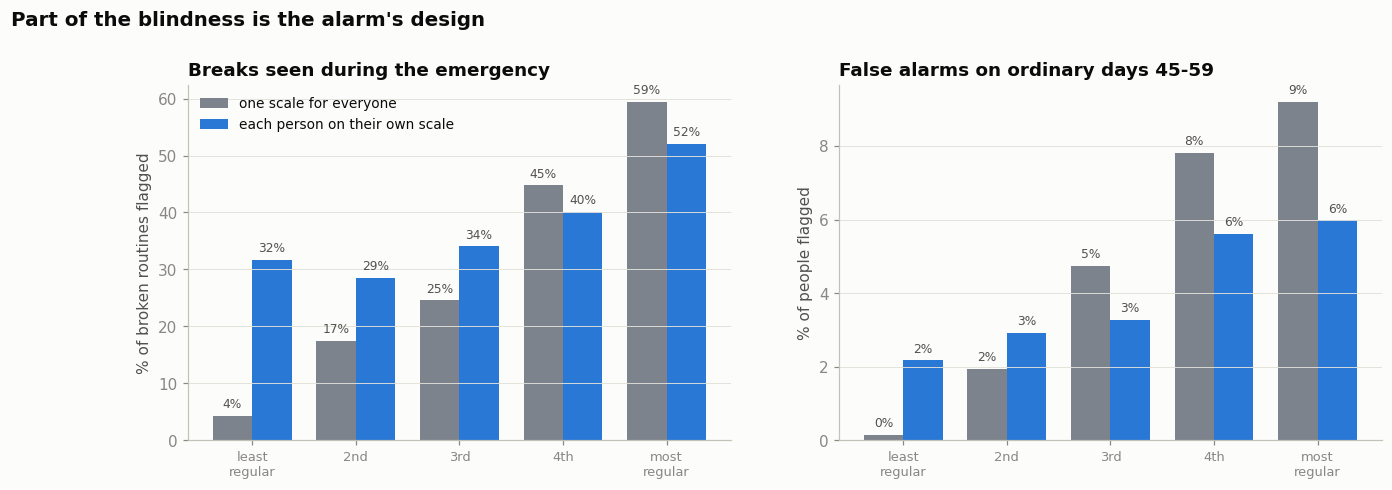

In [4]:
# a fix by design: judge each person's day against their own ordinary variability. Their scale comes from days 0-29, the alarm is set on
# days 30-44 (5% flagged) and monitoring starts on day 45, exactly as for the one-scale alarm, so the two are compared like for like
base = A.loc[:, 0:29]
enough = base.notna().sum(axis=1) >= 10                             # at least ten readable days to know someone's own scale
m_, s_ = base.mean(axis=1), base.std(axis=1).where(enough)
Zown = A.sub(m_, axis=0).div(s_, axis=0)                            # people without enough days get no evidence (NaN, adds nothing)
alarm_own, h_own, path_own = run_alarm(Zown, 0.5)
ev["seen_own"], ev["early_own"] = alarm_own.between(60, 74), alarm_own.between(45, 59)
tab_own = seen_table("seen_own", "early_own")
print(f"each person on their own scale: k 0.5, h {h_own:.2f} | {enough.mean():.1%} of people have their own scale"
      f" | breaks seen {ev.seen_own[ev.broke].mean():.3f}, held flagged {ev.seen_own[~ev.broke].mean():.3f}")
both = pd.concat({"one scale": tab_one, "own scale": tab_own}, axis=1)
print(both.round(3).to_string())
kind_own = ev.groupby("kind").apply(lambda g: g.seen_own[g.broke].mean(), include_groups=False).reindex(ORDER)
print(pd.DataFrame({"one scale": kind_one["breaks seen"], "own scale": kind_own}).round(3).to_string())
LOG["own_scale"] = {"h": round(float(h_own), 3), "people_with_own_scale": round(float(enough.mean()), 4), "by_fifth": tab_own.round(4).to_dict(orient="index"),
                    "breaks_seen_by_kind": kind_own.round(4).to_dict()}
gap = {d: float(t_["breaks seen"].max() - t_["breaks seen"].min()) for d, t_ in [("one", tab_one), ("own", tab_own)]}
print(f"gap in breaks seen between the most and the least seen fifth (equal opportunity): one scale {gap['one']:.3f}, own scale {gap['own']:.3f}")
LOG["equal_opportunity_gap"] = {k_: round(v, 4) for k_, v in gap.items()}
LOG["overall"] = {d: {"breaks seen": round(float(ev[f"seen_{d}"][ev.broke].mean()), 4), "held flagged": round(float(ev[f"seen_{d}"][~ev.broke].mean()), 4),
                      "false alarm 45-59": round(float(ev[f"early_{d}"].mean()), 4)} for d in ["one", "own"]}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
xx = np.arange(5); w = 0.38
for ax, col, title, ylabel in [(axes[0], "breaks seen", "Breaks seen during the emergency", "% of broken routines flagged"),
                               (axes[1], "false alarm, days 45-59", "False alarms on ordinary days 45-59", "% of people flagged")]:
    ax.bar(xx - w / 2, tab_one[col] * 100, width=w, color=GREY, label="one scale for everyone")
    ax.bar(xx + w / 2, tab_own[col] * 100, width=w, color=C[0], label="each person on their own scale")
    off = max(tab_one[col].max(), tab_own[col].max()) * 100 * 0.015
    for x_, v1, v2 in zip(xx, tab_one[col], tab_own[col]):
        ax.text(x_ - w / 2, v1 * 100 + off, f"{v1:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e"); ax.text(x_ + w / 2, v2 * 100 + off, f"{v2:.0%}", ha="center", va="bottom", fontsize=8, color="#52514e")
    ax.set_xticks(xx); ax.set_xticklabels([f.replace(" ", "\n", 1) for f in FIFTH], fontsize=8.5); ax.xaxis.grid(False); ax.set(title=title, ylabel=ylabel)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Part of the blindness is the alarm's design", x=0.01, ha="left", fontweight="bold", fontsize=13, y=1.04)
save(fig, "f49_own_scale_alarm")

               habit evidence, one scale  habit evidence, own scale  Chronos-2 forecast error
fifth                                                                                        
least regular                      0.611                      0.613                     0.818
2nd                                0.592                      0.611                     0.753
3rd                                0.624                      0.625                     0.766
4th                                0.713                      0.705                     0.746
most regular                       0.844                      0.833                     0.765


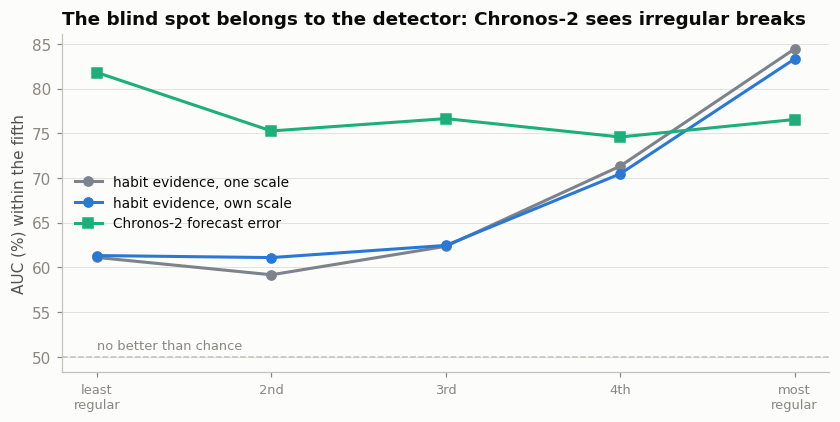

In [5]:
# is it the detector or the data? An independent check: Chronos-2, a pretrained forecaster that never saw our habit model (notebook 05),
# scores each person by how much worse its forecast got in the emergency. If it too fails on irregular people, the limit is in the data.
# AUC within each fifth: how well a score separates people whose routine broke from people whose routine held, among similar people
from sklearn.metrics import roc_auc_score
chron = pd.read_parquet(PROC / "chronos_scores.parquet")
ev["chronos"] = chron.chronos_score.reindex(ev.index)
ev["sum_one"] = A.loc[:, 60:74].fillna(0).sum(axis=1)                 # evidence summed over the emergency, one scale
ev["sum_own"] = Zown.loc[:, 60:74].fillna(0).sum(axis=1)              # the same on each person's own scale
def auc_in(g, col):
    g = g.dropna(subset=[col]); return roc_auc_score(g.broke, g[col]) if g.broke.nunique() == 2 else np.nan
aucs = ev.groupby("fifth", observed=True).apply(lambda g: pd.Series({"habit evidence, one scale": auc_in(g, "sum_one"),
        "habit evidence, own scale": auc_in(g, "sum_own"), "Chronos-2 forecast error": auc_in(g, "chronos")}), include_groups=False)
print(aucs.round(3).to_string())
LOG["auc_by_fifth"] = aucs.round(4).to_dict(orient="index")
fig, ax = plt.subplots(figsize=(9, 4))
for (col, c_), mk in zip([("habit evidence, one scale", GREY), ("habit evidence, own scale", C[0]), ("Chronos-2 forecast error", C[2])], ["o", "o", "s"]):
    ax.plot(np.arange(5), aucs[col] * 100, color=c_, marker=mk, lw=2, label=col)
ax.axhline(50, color="#c3c2b7", lw=1, ls="--"); ax.text(0, 50.8, "no better than chance", ha="left", fontsize=8.5, color="#898781")
ax.set_xticks(np.arange(5)); ax.set_xticklabels([f.replace(" ", "\n", 1) for f in FIFTH], fontsize=8.5); ax.xaxis.grid(False)
ax.set(ylabel="AUC (%) within the fifth", title="The blind spot belongs to the detector: Chronos-2 sees irregular breaks"); ax.legend(frameon=False, fontsize=9, loc="center left")
save(fig, "f50_independent_check")

budget: 1,427 of 7,135 people (20%); choosing at random finds 20% of breaks in every group | risk from fm_tabpfn35_test_scores.parquet
 day                                         rule  all breaks found  least regular two fifths  most regular fifth
  60                       ordinary-day risk only             0.351                     0.046               0.756
  60                          evidence, one scale             0.410                     0.210               0.609
  60                          evidence, own scale             0.389                     0.283               0.513
  60 own scale, budget split evenly by regularity             0.366                     0.317               0.447
  61                       ordinary-day risk only             0.351                     0.046               0.756
  61                          evidence, one scale             0.426                     0.202               0.660
  61                          evidence, own scale             0.419

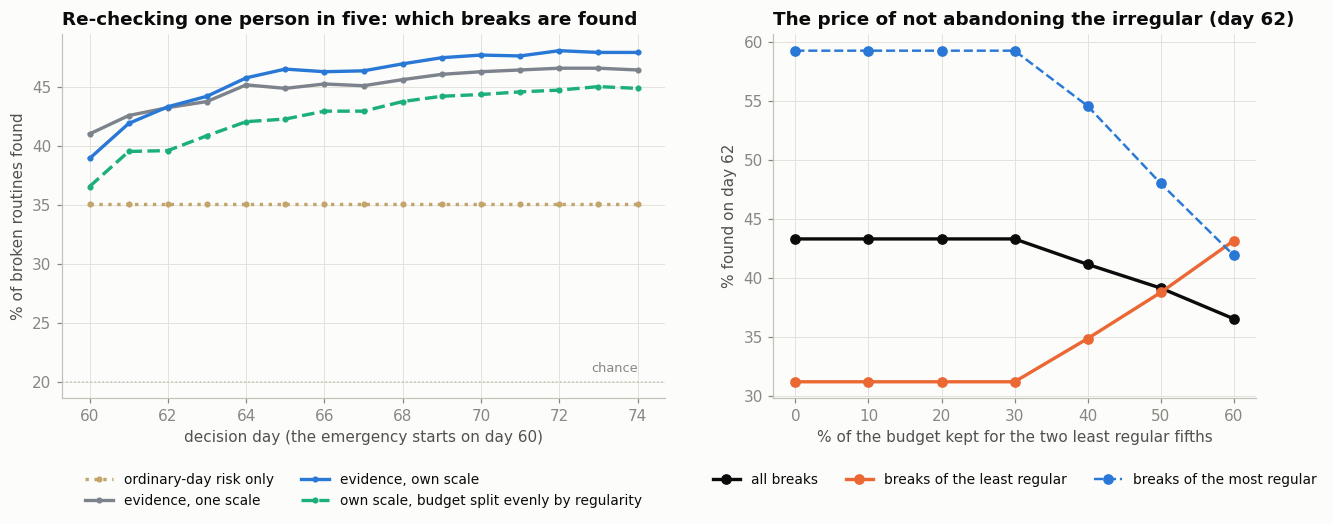

In [6]:
# whom to re-observe: a city can afford to re-observe one person in five. On decision day D it ranks people by the evidence gathered since
# the emergency began (one scale, or each on their own scale), or by the pretrained model's risk from ordinary days alone (notebook 05),
# or it splits the budget evenly across the five fifths of regularity. On the right: keeping a growing share for the two least regular
# fifths, filled by their own-scale evidence. Ties go to the higher ordinary-day risk
risk_file = next(p for p in [PROC / "fm_tabpfn35_test_scores.parquet", PROC / "fm_tabicl_test_scores.parquet"] if p.exists())
risk = pd.Series(pd.read_parquet(risk_file).p.to_numpy(), index=T.index[T.split == "eval"]).reindex(ev.index).fillna(0).to_numpy()
y = ev.broke.to_numpy(); quiet = ev.fifth.isin(FIFTH[:2]).to_numpy(); loud = (ev.fifth == FIFTH[-1]).to_numpy()
BUDGET = 0.2; K = int(round(BUDGET * len(ev)))
fifth_id = ev.fifth.cat.codes.to_numpy()
def pick_even(score):
    """the budget split evenly across the five fifths, each share filled by the highest evidence inside the fifth"""
    score = score + 1e-6 * risk; out = []
    for f in range(5):
        pool = np.where(fifth_id == f)[0]; out.append(pool[np.argsort(-score[pool], kind="stable")][: K // 5])
    return np.concatenate(out)
def pick(score, reserve=0.0):
    score = score + 1e-6 * risk                                     # ties broken by the ordinary-day risk
    n_res = int(round(reserve * K))
    pool = np.where(quiet)[0]
    res = pool[np.argsort(-score[pool], kind="stable")][:n_res] if n_res else np.array([], int)
    rest = np.setdiff1d(np.arange(len(score)), res, assume_unique=True)
    rest = rest[np.argsort(-score[rest], kind="stable")][: K - n_res]
    return np.r_[res, rest].astype(int)
def found(sel, mask=None):
    mask = np.ones(len(y), bool) if mask is None else mask.astype(bool)
    hit = np.zeros(len(y), bool); hit[sel] = True
    return (hit & y & mask).sum() / (y & mask).sum()
sel_risk = pick(np.zeros(len(y)))
rows = []
for D in range(60, 75):
    e1, e2 = A.loc[:, 60:D].fillna(0).sum(axis=1).to_numpy(), Zown.loc[:, 60:D].fillna(0).sum(axis=1).to_numpy()
    for name, sel in [("ordinary-day risk only", sel_risk), ("evidence, one scale", pick(e1)), ("evidence, own scale", pick(e2)),
                      ("own scale, budget split evenly by regularity", pick_even(e2))]:
        rows.append((D, name, found(sel), found(sel, quiet), found(sel, loud)))
tri = pd.DataFrame(rows, columns=["day", "rule", "all breaks found", "least regular two fifths", "most regular fifth"])
print(f"budget: {K:,} of {len(ev):,} people ({BUDGET:.0%}); choosing at random finds {BUDGET:.0%} of breaks in every group | risk from {risk_file.name}")
print(tri[tri.day.isin([60, 61, 62, 63, 64, 67, 74])].round(3).to_string(index=False))
e62 = Zown.loc[:, 60:62].fillna(0).sum(axis=1).to_numpy()
res_rows = []
for r in [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]:
    sel = pick(e62, r); res_rows.append((r, found(sel), found(sel, quiet), found(sel, loud)))
res = pd.DataFrame(res_rows, columns=["kept for the least regular", "all breaks found", "least regular two fifths", "most regular fifth"])
print("day 62, own scale, keeping part of the budget for the least regular:"); print(res.round(3).to_string(index=False))
LOG["triage"] = {"budget": BUDGET, "risk_model": risk_file.name,
                 "by_day": tri.round(4).to_dict(orient="records"), "reserve_day62": res.round(4).to_dict(orient="records")}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
for (name, g), col, ls in zip(tri.groupby("rule", sort=False), ["#c3a46b", GREY, C[0], C[2]], [":", "-", "-", "--"]):
    axes[0].plot(g.day, g["all breaks found"] * 100, color=col, lw=2.2, ls=ls, marker="o", ms=3, label=name)
axes[0].axhline(BUDGET * 100, color="#c3c2b7", lw=1, ls=":"); axes[0].text(74, BUDGET * 100 + 0.8, "chance", ha="right", fontsize=8.5, color="#898781")
axes[0].set(xlabel="decision day (the emergency starts on day 60)", ylabel="% of broken routines found", title="Re-checking one person in five: which breaks are found")
axes[0].legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
axes[1].plot(res["kept for the least regular"] * 100, res["all breaks found"] * 100, color="#0b0b0b", lw=2.2, marker="o", label="all breaks")
axes[1].plot(res["kept for the least regular"] * 100, res["least regular two fifths"] * 100, color=VERM, lw=2.2, marker="o", label="breaks of the least regular")
axes[1].plot(res["kept for the least regular"] * 100, res["most regular fifth"] * 100, color=C[0], lw=1.6, marker="o", ls="--", label="breaks of the most regular")
axes[1].set(xlabel="% of the budget kept for the two least regular fifths", ylabel="% found on day 62", title="The price of not abandoning the irregular (day 62)")
axes[1].legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
save(fig, "f51_triage")

In [7]:
# the rules in plain words, with the numbers they rest on, and the data for the interactive figure on the site
t1, to = LOG["one_scale"]["by_fifth"], LOG["own_scale"]["by_fifth"]
r62 = tri[tri.day == 62].set_index("rule")
a_h, a_c = aucs["habit evidence, own scale"], aucs["Chronos-2 forecast error"]
if a_c.iloc[0] - a_h.iloc[0] >= 0.05:
    VERDICT = (f"The blind spot is in how the alarm looks, not in the data. Among the least regular fifth the habit evidence separates broken from held "
               f"routines only weakly (AUC {a_h.iloc[0]:.2f}), while Chronos-2, asking only whether the person's days stopped following their own past,\n   "
               f"reaches {a_c.iloc[0]:.2f} (most regular fifth: {a_h.iloc[-1]:.2f} and {a_c.iloc[-1]:.2f}). The alarm looks for the change most people made; irregular people changed their own way.")
else:
    VERDICT = (f"An independent detector finds the same blind spot, so the limit is in the data: in the least regular fifth Chronos-2 reaches AUC {a_c.iloc[0]:.2f} "
               f"and the habit evidence {a_h.iloc[0]:.2f} (most regular fifth: {a_c.iloc[-1]:.2f} and {a_h.iloc[-1]:.2f}).")
LOG["verdict"] = VERDICT
print(f"""
1. Irregular people's routines break less often ({t1[FIFTH[0]]['broke']:.0%} of the least regular fifth against {t1[FIFTH[-1]]['broke']:.0%} of the most regular), but when they break
   the break is about as big (median rise in surprise {why.break_size.iloc[0]:.2f} against {why.break_size.iloc[-1]:.2f}). It is quieter: in their daily evidence it moved
   {why.d_prime.iloc[0]:.2f} of an ordinary day's wobble against {why.d_prime.iloc[-1]:.2f}, so seeing it takes about {why.days_needed.iloc[0]:.0f} days of data against {why.days_needed.iloc[-1]:.0f}. The emergency lasted 15.
2. One alarm for everyone sees what its grid makes legible: {t1[FIFTH[0]]['breaks seen']:.0%} of the least regular fifth's breaks against {t1[FIFTH[-1]]['breaks seen']:.0%} of the most
   regular's. Judging each person on their own scale sees {to[FIFTH[0]]['breaks seen']:.0%} and {to[FIFTH[-1]]['breaks seen']:.0%}; the gap between the most and least seen fifth falls from
   {LOG['equal_opportunity_gap']['one']:.0%} to {LOG['equal_opportunity_gap']['own']:.0%}, with false alarms on ordinary days {LOG['overall']['one']['false alarm 45-59']:.1%} against {LOG['overall']['own']['false alarm 45-59']:.1%}.
3. {VERDICT}
4. Re-observing one person in five on day 62 by own-scale evidence finds {r62.loc['evidence, own scale', 'all breaks found']:.0%} of all breaks (ordinary-day risk alone: {r62.loc['ordinary-day risk only', 'all breaks found']:.0%},
   one scale: {r62.loc['evidence, one scale', 'all breaks found']:.0%}, chance: {BUDGET:.0%}). Of the least regular two fifths' breaks it finds {r62.loc['evidence, own scale', 'least regular two fifths']:.0%} (one scale:
   {r62.loc['evidence, one scale', 'least regular two fifths']:.0%}); splitting the budget evenly by regularity finds {r62.loc['own scale, budget split evenly by regularity', 'least regular two fifths']:.0%} of theirs and
   {r62.loc['own scale, budget split evenly by regularity', 'all breaks found']:.0%} of all breaks.
""")
# the interactive figure: every evaluation person as a dot (how regular, how big the break), and the day each alarm design first flags them
rng = np.random.default_rng(SEED)
take = np.sort(rng.choice(len(ev), min(len(ev), 4000), replace=False))
sub = ev.iloc[take]
day_or_none = lambda s: [int(v) if np.isfinite(v) else None for v in s]
web = {"note": "evaluation people of notebook 04 (a random 4,000 if more): x = rank of regularity (0 least, 1 most), y = rise in surprise, alarm day per design (null = never)",
       "x": sub.regularity.rank(pct=True).round(4).tolist(), "y": sub.delta.clip(-0.6, 1.2).round(3).tolist(), "broke": sub.broke.astype(int).tolist(),
       "kind": [ORDER.index(k) for k in sub.kind], "alarm_one": day_or_none(alarm_one.reindex(sub.index).to_numpy()),
       "alarm_own": day_or_none(alarm_own.reindex(sub.index).to_numpy()), "kinds": ORDER,
       "seen_by_day": {d: {f: [round(float(((alarm.reindex(ev.index) <= day) & alarm.reindex(ev.index).ge(60) & ev.broke & (ev.fifth == f)).sum() / (ev.broke & (ev.fifth == f)).sum()), 4)
                           for day in range(59, 75)] for f in FIFTH} for d, alarm in [("one", alarm_one), ("own", alarm_own)]}}
(OUT / "invisible_breaks.json").write_text(json.dumps(web, separators=(",", ":")))
# every evaluation person's evidence day by day (days 0-74) with kind, regularity and label: the material for interactive figures
# made later, so they never need the cluster again (about 2 MB)
ev[["kind", "regularity", "broke", "delta"]].join(A).to_csv(OUT / "day_evidence_eval.csv.gz", float_format="%.4g")
(ROOT / "logs/part3_invisible_log.json").write_text(json.dumps(LOG, indent=2, default=str))
print(f"invisible_breaks.json {(OUT / 'invisible_breaks.json').stat().st_size / 1e3:.0f} KB | log written")


1. Irregular people's routines break less often (13% of the least regular fifth against 30% of the most regular), but when they break
   the break is about as big (median rise in surprise 0.31 against 0.37). It is quieter: in their daily evidence it moved
   0.46 of an ordinary day's wobble against 1.06, so seeing it takes about 29 days of data against 6. The emergency lasted 15.
2. One alarm for everyone sees what its grid makes legible: 4% of the least regular fifth's breaks against 59% of the most
   regular's. Judging each person on their own scale sees 32% and 52%; the gap between the most and least seen fifth falls from
   55% to 23%, with false alarms on ordinary days 4.8% against 4.0%.
3. The blind spot is in how the alarm looks, not in the data. Among the least regular fifth the habit evidence separates broken from held routines only weakly (AUC 0.61), while Chronos-2, asking only whether the person's days stopped following their own past,
   reaches 0.82 (most regular fifth:

In [8]:
# one archive with what this notebook produced, to download from the file browser (save the notebook first)
out = ROOT / "part3_invisible_outputs.zip"
with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(FIG.glob("f4[7-9]_*.png")) + sorted(FIG.glob("f5[01]_*.png")):
        z.write(p, f"figures/{p.name}")
    for p in [OUT / "invisible_breaks.json", OUT / "day_evidence_eval.csv.gz", ROOT / "logs/part3_invisible_log.json", ROOT / "notebooks/06_invisible_breaks.ipynb"]:
        if p.exists(): z.write(p, str(p.relative_to(ROOT)))
        else: print("missing:", p)
print(out, f"{out.stat().st_size / 1e6:.1f} MB")

/projects/ancz7294/yjmob/part3_invisible_outputs.zip 2.0 MB
